<a href="https://colab.research.google.com/github/islamsamian22-ship-it/Python-prohects/blob/main/Titanic_Data_set_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

['Physics Mock QP.docx', '1 Mixture- a substance made when two or more are combined,not chemically bonded.gdoc', '3746_0115876_ORIGSIZE (1).jpg', '3746_0115876_ORIGSIZE.jpg', 'AQA_Biology_Infection and Response KnowIT_GCSE - QUESTIONS-1.docx', 'Itinerary 1028444-1 (1).pdf', 'Itinerary 1028444-1.pdf', 'Abbey DLD International Application Form.pdf', 'Offer Letter ISLAM Samian (1).pdf', 'Contact Form (1).pdf', 'Contact Form.pdf', 'Offer Letter ISLAM Samian.pdf', 'Biomes.pptx', '8464-B-2H-QP-CombinedScienceTrilogy-G-15Jun22-AM.pdf', '8464-C-2H-QP-CombinedScienceTrilogy-G-20Jun22-AM.pdf', '8464-P-2H-QP-CombinedScienceTrilogy-G-23Jun22-AM.pdf', 'Personal statement.gdoc', 'Copy of Personal statement.gdoc', 'Master Copy of Personal statement (1).docx', 'Classroom', 'Samian Islam Resume.docx', 'Copy of Biomes.pptx', 'AQA_Biology_Ecology_KnowIT_GCSE_Questions (1).docx', '1ma1-1f-que-20220521 (1).pdf', '1ma1-2f-que-20220608.pdf', '1ma1-1f-que-20220521.pdf', 'Kami Uploads', 'CamScanner 04-06-2023 

/tmp/ipykernel_1657/434289822.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survival_Status', palette=palette, ax=ax2, order=['Did not Survive', 'Survived'])


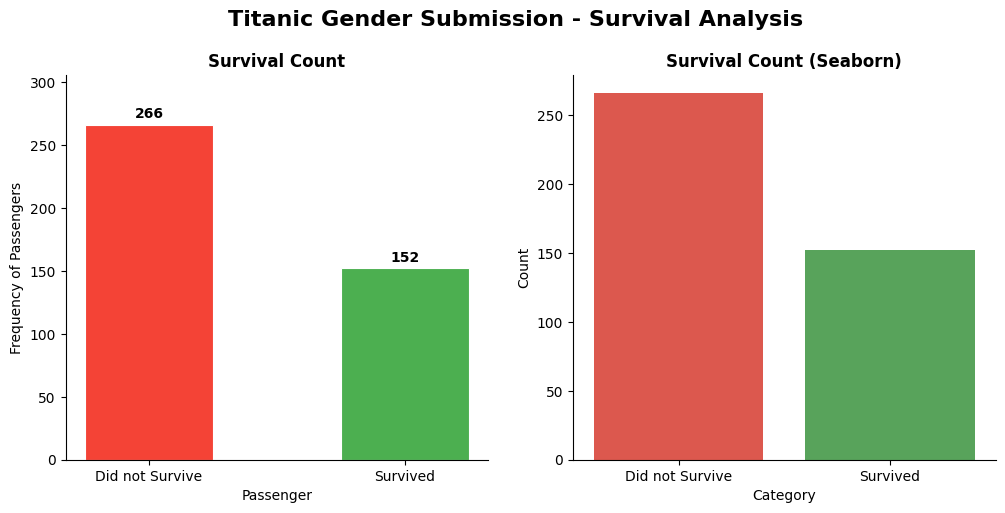

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
print(os.listdir('/content/drive/MyDrive'))


from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/gender_submission.csv')

print("Raw data")
print(df.head())
print(f"\nShape: {df.shape}")
print(f"Null values:\n{df.isnull().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")

df_no_duplicates = df.drop_duplicates()

assert df['Survived'].isin([0,1]).all(), "Unexpected values in Survived column"

df['Survival_Status'] = df['Survived'].map({0: 'Did not Survive', 1: 'Survived'})

print("Cleaned data")
print(df.head())
print(f"\nSurvived value counts:\n{df['Survival_Status'].value_counts()}")

fig, axes = plt.subplots(1,2, figsize=(12,5))
fig.suptitle("Titanic Gender Submission - Survival Analysis", fontsize=16, fontweight='bold', y=1.01)

palette = {'Survived': '#4CAF50', 'Did not Survive': '#F44336'}

ax1 = axes[0]
counts = df['Survival_Status'].value_counts()
colors = [palette[s] for s in counts.index]
bars = ax1.bar(counts.index, counts.values, color=colors, edgecolor='white', linewidth=0.8, width=0.5)
ax1.set_title('Survival Count', fontweight='bold')
ax1.set_ylabel('Frequency of Passengers')
ax1.set_xlabel('Passenger')
for bar, val in zip(bars, counts.values):
  ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3, str(val), ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, counts.max() * 1.15)
sns.despine(ax=ax1)

ax2 = axes[1]
sns.countplot(data=df, x='Survival_Status', palette=palette, ax=ax2, order=['Did not Survive', 'Survived'])
ax2.set_title('Survival Count (Seaborn)', fontweight='bold')
ax2.set_xlabel('Category')
ax2.set_ylabel('Count')
sns.despine(ax=ax2)